In [ ]:
# --- Importing, loading, and scaling data ---
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

# 1) Load data
df = pd.read_csv("../lu2_datasets/Leescatalogus_Opgeschoond.csv")

# 2) Select features
features = [
    "Aantal_paginas",
    "Geschatte_leestijd_min",
    "Gem_woordlengte",
    "Gem_zinslengte_woorden",
    "Aandeel_lange_woorden_pct",
    "Leescomplexiteit_score"
]

X = df[features].copy()

In [10]:
imputer = SimpleImputer(strategy="median")

X_imputed = imputer.fit_transform(X)

In [11]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_imputed)

In [14]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

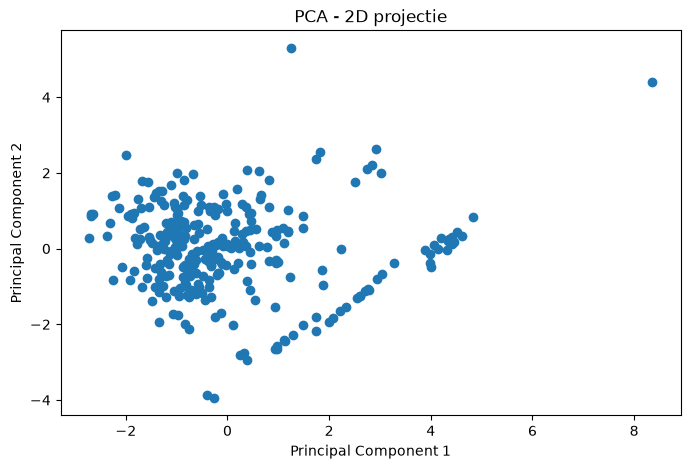

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(X_pca[:, 0], X_pca[:, 1])

plt.title("PCA - 2D projectie")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.show()

In [16]:
print("Verklaarde variantie per component:")
print(pca.explained_variance_ratio_)

print("Totale verklaarde variantie:")
print(pca.explained_variance_ratio_.sum())

Verklaarde variantie per component:
[0.47159964 0.23859144]
Totale verklaarde variantie:
0.7101910772978842


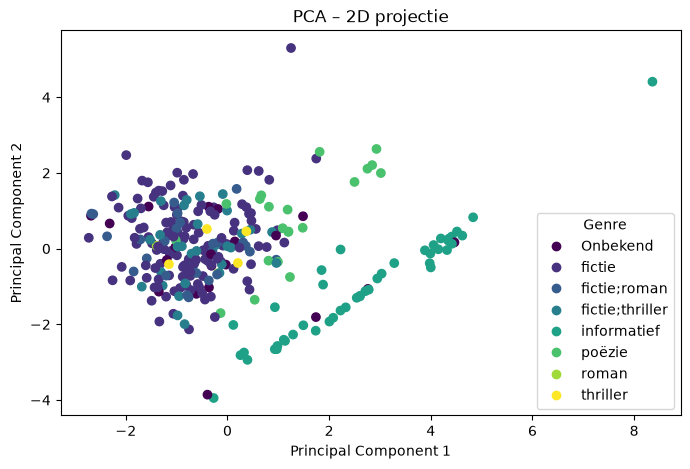

In [18]:
# PCA visualiseren met genre als kleur

genres = df["Genre"].fillna("Onbekend")

plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=pd.Categorical(genres).codes,
    cmap="viridis"
)

plt.title("PCA – 2D projectie")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.legend(
    handles=scatter.legend_elements()[0],
    labels=pd.Categorical(genres).categories,
    title="Genre"
)

plt.show()

**t-SNE**

In [20]:
from sklearn.manifold import TSNE

# t-SNE uitvoeren
tsne = TSNE(
    n_components=2,
    perplexity=30,
    random_state=42
)

X_tsne = tsne.fit_transform(X_scaled)

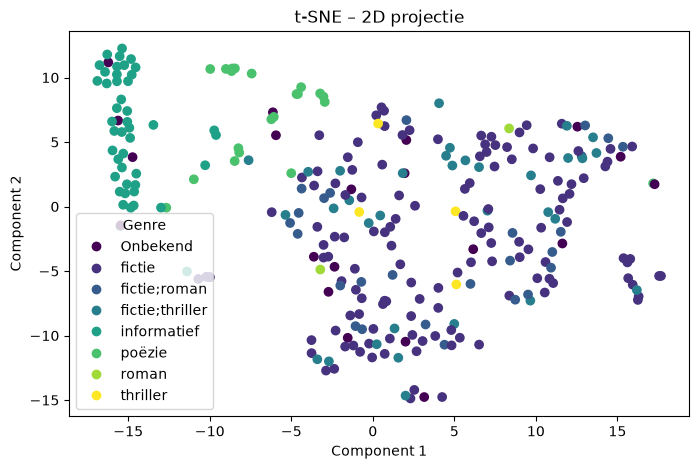

In [21]:
# Genre gebruiken voor de kleuren
genres = df["Genre"].fillna("Onbekend")
genre_codes = pd.Categorical(genres).codes

plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=genre_codes,
    cmap="viridis"
)

plt.title("t-SNE – 2D projectie")
plt.xlabel("Component 1")
plt.ylabel("Component 2")

plt.legend(
    handles=scatter.legend_elements()[0],
    labels=pd.Categorical(genres).categories,
    title="Genre"
)

plt.show()

**UMAP**

In [22]:
import umap
# UMAP uitvoeren
umap_model = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    random_state=42
)

X_umap = umap_model.fit_transform(X_scaled)

/Users/nannalakens/School/Jaar2/P2.1-2.2/Lu2/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/Users/nannalakens/School/Jaar2/P2.1-2.2/Lu2/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


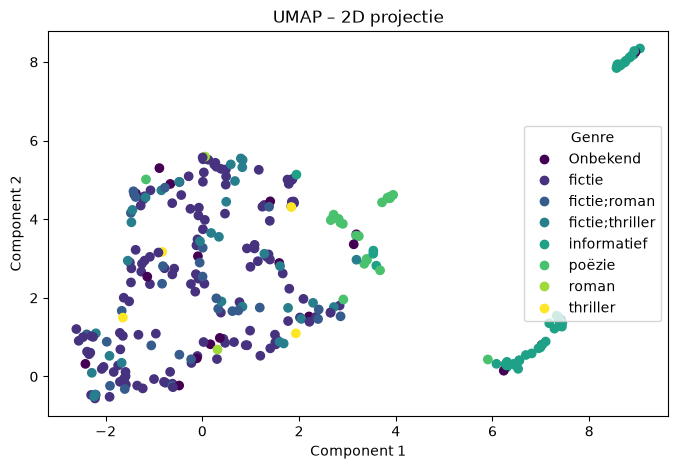

In [23]:
# UMAP visualiseren met Genre als kleur
plt.figure(figsize=(8, 5))

scatter = plt.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=genre_codes,
    cmap="viridis"
)

plt.title("UMAP – 2D projectie")
plt.xlabel("Component 1")
plt.ylabel("Component 2")

plt.legend(
    handles=scatter.legend_elements()[0],
    labels=pd.Categorical(genres).categories,
    title="Genre"
)

plt.show()